# 02 · DLM em painel: seleção AIC e BIC

**Etapa 2 — notebook principal, completo e executável.** Implementa a equação da monografia (27 UFs e efeitos fixos de UF e mês-ano):

$$Y_{i,t}=\alpha_i+\lambda_t+\sum_{k=0}^{K}\beta_k X_{i,t-k}+\varepsilon_{i,t}.$$

\(Y_{i,t}=\Delta\log(I_{i,t})\), \(X_{i,t}=\Delta\log(1+D_{i,t})\). Ajustamos **uma tipologia por vez**, separando os períodos pré e total, sem grupos. **AIC e BIC geram dois modelos selecionados por tipologia e período** a partir da mesma grade de \(K=1,\dots,24\), comparada na mesma amostra.

**Roteiro:** dados e estacionariedade → amostra comum e suporte → estimativas TWFE por MQO para todo K → seleção AIC/BIC → testes FE/RE → covariâncias e cinco hipóteses → BH + proteção de K → auditoria das matrizes → perfis e curvas acumuladas → interpretação. Todas as rotinas de cálculo estão contidas aqui.

## 1. Base, dependências e transformações

As regressões usam a taxa de inadimplência em log-diferença e as contagens por tipologia transformadas como Δlog(1+D). A mesma base auditada é usada nos três notebooks; não confundir diferença do log com log da diferença.

In [1]:
from pathlib import Path
import hashlib, os, warnings, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.diagnostic import acorr_ljungbox

# Executável a partir da raiz do repositório ou da pasta notebooks/.
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT=ROOT.parent
if not (ROOT/'data').exists():
    raise FileNotFoundError('Execute a partir da raiz do repositório ou de notebooks/.')
BASE = Path(os.environ.get('TCC_BASE_CSV',str(ROOT/'data/processed/df_tcc_2013_2024.csv')))
if not BASE.exists():
    raise FileNotFoundError(f'Base mensal não versionada: {BASE}. Consulte data/README.md.')
EXPECTED_HASH='46f4f8408f5f6a809de2601b5c313ea52ee5992ed5a65ede5246c57d28767e36'
actual_sha=hashlib.sha256(BASE.read_bytes()).hexdigest()
assert actual_sha==EXPECTED_HASH, f'Hash da base diferente do painel auditado: {actual_sha}'
SOURCE=BASE
OUT=ROOT/'outputs/tables/revisao_estadual_20261019'
AUD=ROOT/'outputs/tables/auditoria_metodologica_20261020'
OUT.mkdir(parents=True,exist_ok=True)
AUD.mkdir(parents=True,exist_ok=True)
TIPOS=['tipo_alagamentos','tipo_chuvas_intensas','tipo_doencas_infecciosas','tipo_enxurradas','tipo_erosao','tipo_estiagem_e_seca','tipo_granizo','tipo_incendio_florestal','tipo_inundacoes','tipo_movimento_de_massa','tipo_onda_de_calor_e_baixa_umidade','tipo_onda_de_frio','tipo_outros','tipo_rompimento_colapso_de_barragens','tipo_tornado','tipo_vendavais_e_ciclones']
print('Base auditada:',BASE.name,'| SHA-256:',actual_sha[:16]+'…')

Base auditada: df_tcc_2013_2024.csv | SHA-256: 46f4f8408f5f6a80…


In [2]:
def load():
    df=pd.read_csv(SOURCE,sep=';',encoding='utf-8-sig');df['data']=pd.to_datetime(df['mes_ano']+'-01');df=df.sort_values(['uf','data']).reset_index(drop=True)
    assert len(df)==3888 and df.uf.nunique()==27 and df.data.nunique()==144 and not df.duplicated(['uf','data']).any()
    assert len(TIPOS)==16 and not df[TIPOS].isna().any().any()
    assert np.allclose(100*df.carteira_inadimplencia_total/df.carteira_ativa_total,df.taxa_inadimplencia,rtol=0,atol=1e-9)
    assert np.isfinite(np.log(df.taxa_inadimplencia)).all() and (df[TIPOS]>=0).all().all()
    for c in ['taxa_inadimplencia']+TIPOS:
        df[('y' if c=='taxa_inadimplencia' else 'x_'+c)]=df.groupby('uf')[c].transform(lambda v: np.log(v).diff() if c=='taxa_inadimplencia' else np.log1p(v).diff())
    return df

df=load()
print(df.uf.nunique(),"UFs;",df.mes_ano.nunique(),"meses;",len(df),"registros")

27 UFs; 144 meses; 3888 registros


## 2. Estacionariedade e decisão sobre transformações

ADF: H₀ de raiz unitária. KPSS: H₀ de estacionariedade. Os testes são diagnósticos das séries transformadas; quando divergem, não concluímos que há ou não estacionariedade por decreto. Mantemos Δlog para comparabilidade dos modelos.

In [3]:
from statsmodels.tsa.stattools import adfuller, kpss

def diagnostico_estacionariedade(df, apenas_dependente=False):
    linhas=[]
    for periodo, limite in [('Pré','2020-01'),('Total','2024-12')]:
        d=df[df.mes_ano<=limite]
        for uf,g in d.groupby('uf'):
            cols=['y'] if apenas_dependente else ['y']+['x_'+tipo for tipo in TIPOS]
            for col in cols:
                v=g[col].dropna().to_numpy(float)
                rec={'periodo':periodo,'uf':uf,'serie':col,'n':len(v)}
                if len(v)<20 or np.ptp(v)<1e-10:
                    rec.update(p_ADF=np.nan,p_KPSS=np.nan,status='constante ou sem suporte');linhas.append(rec);continue
                try:rec['p_ADF']=float(adfuller(v,regression='c',autolag='BIC')[1])
                except Exception as exc:rec['p_ADF']=np.nan;rec['erro_ADF']=type(exc).__name__
                try:
                    with warnings.catch_warnings(record=True) as w:
                        warnings.simplefilter('always')
                        rec['p_KPSS']=float(kpss(v,regression='c',nlags='auto')[1])
                    rec['avisos_KPSS']=len(w)
                except Exception as exc:rec['p_KPSS']=np.nan;rec['erro_KPSS']=type(exc).__name__
                a,k=rec['p_ADF'],rec['p_KPSS']
                rec['status']=('compatível com estacionariedade' if a<.05 and k>=.05 else
                    'sinais contrários' if a>=.05 and k<.05 else 'inconclusivo/divergente') if np.isfinite(a) and np.isfinite(k) else 'inconclusivo/sem teste'
                linhas.append(rec)
    return pd.DataFrame(linhas)

In [4]:
est=diagnostico_estacionariedade(df,apenas_dependente=True)
display(est.groupby(['periodo','status']).size().rename('n_UFs').reset_index());print('Resultados KPSS indisponíveis:',est.p_KPSS.isna().sum())

,periodo,status,n_UFs
0,Pré,compatível com estacionariedade,16
1,Pré,inconclusivo/divergente,10
2,Pré,sinais contrários,1
3,Total,compatível com estacionariedade,24
4,Total,inconclusivo/divergente,2
5,Total,sinais contrários,1


Resultados KPSS indisponíveis: 0


## 3. Como os efeitos fixos são estimados?

A transformação de duplo centramento (`dm`, Frisch–Waugh–Lovell) remove o intercepto de UF e o efeito do mês-ano na amostra balanceada. Em seguida estimamos os coeficientes de cada lag por MQO. A identificação vem de variações **dentro de cada UF** que não são comuns ao mesmo mês-ano. O grid K=1..24 usa **mesma amostra inicial após 24 lags**, para que AIC/BIC não sejam comparados sobre janelas diferentes.

**Critério de suporte histórico:** pelo menos cinco UFs com registros na janela e dez UF-meses positivos. Três aplicações pré-pandemia não atingiram o suporte. Não removemos ou reclassificamos as 16 tipologias do Atlas.

Para cada K, maximizamos a verossimilhança gaussiana correspondente a MQO e computamos AIC e BIC incluindo a contagem de efeitos fixos. O modelo pode ser selecionado com K=1, que contém β₀ e β₁ (não apenas β₁).

In [5]:
def bh(df,groupcols,pcol='p',outcol='q_bh'):
    # Família planejada de 16 tipologias por UF×período (ou endpoint DLM).
    # Ausência de estimativa nunca é interpretada como p observado; um p=1
    # apenas ocupa a posição planejada para tornar o ajuste conservador.
    df[outcol]=np.nan
    for _,inds in df.groupby(groupcols,sort=False,dropna=False).groups.items():
        ps=df.loc[inds,pcol].to_numpy(float)
        assert len(ps)<=16, f'Família deveria ter até 16 tipologias, recebeu {len(ps)} para {groupcols}'
        full=np.r_[np.nan_to_num(ps,nan=1.0).clip(0,1),np.ones(16-len(ps))]
        q=multipletests(full,method='fdr_bh')[1][:len(ps)]
        q[~np.isfinite(ps)]=np.nan
        df.loc[inds,outcol]=q
    df['rejeicao_nominal']=df[pcol].lt(.05) & df[pcol].notna()
    df['rejeicao_bh']=df[outcol].lt(.05) & df[outcol].notna()
    return df

def dm(A):
    return A-A.mean(axis=0,keepdims=True)-A.mean(axis=1,keepdims=True)+A.mean(axis=(0,1),keepdims=True)


def design_panel(arrx,y,K,T,G):
    # arrx [G,144], same y; start base period 2013-01, diff requires t>=1 and 24 lags -> t>=25.
    tt=np.arange(25,T);v=dm(y[:,tt,None])[:,:,0].reshape(-1)
    X=dm(np.stack([arrx[:,tt-k] for k in range(K+1)],axis=2)).reshape(-1,K+1)
    return X,v,len(tt)


def robust_cov(X,e,K,G,T,kind):
    N=len(e);p=K+1;ptotal=G+T-1+p; bread=np.linalg.pinv(X.T@X,hermitian=True)
    if kind=='cluster_uf':
        s=np.einsum('gtk,gt->gk',X.reshape(G,T,p),e.reshape(G,T))
        meat=s.T@s
        factor=G/(G-1)*(N-1)/(N-ptotal)
        return factor*bread@meat@bread, G-1
    if kind=='dk_regra':L=int(np.floor(4*(T/100)**(2/9)))
    elif kind=='dk6':L=6
    elif kind=='dk12':L=12
    else:raise ValueError(kind)
    scores=np.einsum('gtk,gt->tk',X.reshape(G,T,p),e.reshape(G,T))
    meat=scores.T@scores
    for h in range(1,min(T,L+1)):
        lag=scores[h:].T@scores[:-h];meat+=(1-h/(L+1))*(lag+lag.T)
    factor=N/(N-ptotal)
    return factor*bread@meat@bread, T-1


def wald(beta,cov,df_res,endpoint):
    K=len(beta)-1;p=K+1
    if endpoint=='beta0':C=np.eye(p)[[0]]
    elif endpoint=='soma0K':C=np.ones((1,p))
    elif endpoint=='soma1K':C=np.concatenate([np.zeros((1,1)),np.ones((1,p-1))],axis=1)
    elif endpoint=='conjunto0K':C=np.eye(p)
    elif endpoint=='conjunto1K':C=np.eye(p)[1:]
    else:raise ValueError(endpoint)
    if not C.size:return None
    diff=C@beta;V=C@cov@C.T;rank=np.linalg.matrix_rank(V,tol=1e-15);r=C.shape[0]
    if rank<r or np.min(np.linalg.eigvalsh(V))<=0:return dict(p=np.nan,status='covariância singular no contraste')
    if r==1:
        se=float(np.sqrt(V[0,0]));t=float(diff[0]/se);pv=float(2*stats.t.sf(abs(t),df_res));ci=stats.t.ppf(.975,df_res)*se
        return dict(p=pv,estimate=float(diff[0]),se=se,ic_inf=float(diff[0]-ci),ic_sup=float(diff[0]+ci),estatistica=t,df_num=1,status='calculado')
    stat=float(diff@np.linalg.solve(V,diff)/r);return dict(p=float(stats.f.sf(stat,r,df_res)),estimate=np.nan,se=np.nan,ic_inf=np.nan,ic_sup=np.nan,estatistica=stat,df_num=r,status='calculado')


def fe_re_tests(X,y,G,T,K):
    """Testes clássicos de painel na amostra comum com dummies temporais.
    Resultados com ressalvas: F clássico e LM assumem especificação homocedástica.
    RE GLS quasi-demeaned por estimativas de componentes de variância.
    """
    N=G*T;p=K+1
    # X e y são pré TWFE; para FE usar DM.
    XX=X.reshape(G,T,p);yy=y.reshape(G,T)
    tt=np.tile(np.eye(T)[:,1:],(G,1))
    pooled=np.column_stack([np.ones(N),tt,X]);bp=np.linalg.lstsq(pooled,y,rcond=None)[0];ep=y-pooled@bp;rsspool=float(ep@ep);dfpool=N-pooled.shape[1]
    fex=dm(XX).reshape(N,p);fey=dm(yy[:,:,None]).reshape(N);bf=np.linalg.lstsq(fex,fey,rcond=None)[0];ef=fey-fex@bf;rssfe=float(ef@ef);dffe=N-(G+T-1+p)
    F=max(0,(rsspool-rssfe)/(G-1))/(rssfe/dffe);pF=float(stats.f.sf(F,G-1,dffe))
    rr=ep.reshape(G,T);ratio=float((rr.sum(axis=1)**2).sum()/(ep@ep));lm=G*T/(2*(T-1))*max(0,ratio-1)**2;pLM=float(.5*stats.chi2.sf(lm,1)) if ratio>1 else 1.0
    sigmae2=rssfe/dffe; sigma_u2=max(0,float(np.var(rr.mean(axis=1),ddof=1)-sigmae2/T));theta=1-np.sqrt(sigmae2/(sigmae2+T*sigma_u2)) if sigma_u2>0 else 0.0
    # transformed including constant and month dummies, GLS with RE state intercept
    R=np.column_stack([np.ones(N),tt,X]);R3=R.reshape(G,T,-1);Rq=(R3-theta*R3.mean(axis=1,keepdims=True)).reshape(N,-1);yq=(yy-theta*yy.mean(axis=1,keepdims=True)).reshape(N)
    br=np.linalg.lstsq(Rq,yq,rcond=None)[0][-p:]
    Sxx=fex.T@fex;Vf=sigmae2*np.linalg.pinv(Sxx)
    Sr=np.linalg.pinv(Rq.T@Rq);Vr=sigmae2*Sr[-p:,-p:]
    diff=bf-br;V=Vf-Vr;evals=np.linalg.eigvalsh(V)
    if np.min(evals)>1e-12:
        H=float(diff@np.linalg.solve(V,diff));pH=float(stats.chi2.sf(H,p));hausman='calculado'
    else:H=np.nan;pH=np.nan;hausman='diferença de covariâncias não definida positiva (teste clássico indisponível)'
    return dict(teste_F=F,p_F=pF,teste_LM=lm,p_LM=pLM,teste_Hausman=H,p_Hausman=pH,status_Hausman=hausman,theta_RE=theta,sigma2_RE=sigma_u2,ssr_FE=rssfe,ssr_pooled=rsspool,coef_FE=str(bf.tolist()),coef_RE=str(br.tolist()))


def dlm(df):
    selected=[];tests=[];candidates=[];comparacoes=[];diagnostics=[]
    for periodo,stop in [('Pré','2020-01'),('Total','2024-12')]:
        g=df[df.mes_ano<=stop].copy();ufs=sorted(g.uf.unique());G=len(ufs);TT=g.mes_ano.nunique()
        y=np.stack([g[g.uf==u].y.to_numpy(float) for u in ufs]);assert G==27
        for tipo in TIPOS:
            x=np.stack([g[g.uf==u]['x_'+tipo].to_numpy(float) for u in ufs]);
            # Histórico: aplica mínimo de 5 UFs contemporaneamente expostas na amostra de equações.
            tt=np.arange(25,TT);contemporaneous=(g[g.mes_ano.isin(sorted(g.mes_ano.unique())[25:])].groupby('uf')[tipo].sum()>0)
            n_ufs=int(contemporaneous.sum());npos=int((np.stack([g[g.uf==u][tipo].to_numpy(float) for u in ufs])[:,tt]>0).sum())
            if n_ufs<5 or npos<10:
                for crit in ['AIC','BIC']:selected.append(dict(periodo=periodo,tipologia=tipo,criterio=crit,status='suporte insuficiente',K=np.nan,N=G*len(tt),UFs_contemporaneas=n_ufs))
                continue
            fit={}
            for K in range(1,25):
                X,Y,T=design_panel(x,y,K,TT,G)
                if np.linalg.matrix_rank(X)!=K+1:continue
                b=np.linalg.lstsq(X,Y,rcond=None)[0];e=Y-X@b;RSS=e@e
                if RSS<=0:continue
                ptotal=G+T-1+K+1;n=len(Y);ll=-n/2*(np.log(2*np.pi)+1+np.log(RSS/n));aic=-2*ll+2*ptotal;bic=-2*ll+np.log(n)*ptotal
                fit[K]=(aic,bic,b,e,X,Y,T,RSS)
                candidates.append(dict(periodo=periodo,tipologia=tipo,K=K,AIC=aic,BIC=bic,N=n,parametros=ptotal,SSR=RSS,loglike=ll,status='estimado'))
            if not fit:
                for crit in ['AIC','BIC']:selected.append(dict(periodo=periodo,tipologia=tipo,criterio=crit,status='posto insuficiente',K=np.nan,N=G*len(tt)))
                continue
            for crit,pos in [('AIC',0),('BIC',1)]:
                K=min(fit,key=lambda v:(fit[v][pos],v));aic,bic,b,e,X,Y,T,RSS=fit[K]
                selected.append(dict(periodo=periodo,tipologia=tipo,criterio=crit,status='estimado',K=K,AIC=aic,BIC=bic,N=len(Y),meses=T,UFs_contemporaneas=n_ufs,uf_mes_positivos=npos))
                for covlabel in ['cluster_uf','dk_regra','dk6','dk12']:
                    cov,df_res=robust_cov(X,e,K,G,T,covlabel)
                    for endpoint in ['beta0','soma0K','soma1K','conjunto0K','conjunto1K']:
                        test=wald(b,cov,df_res,endpoint)
                        if test is not None:tests.append(dict(periodo=periodo,tipologia=tipo,criterio=crit,K=K,covariancia=covlabel,endpoint=endpoint,gl_residuais=df_res,**test))
                if crit=='BIC':
                    # Two-way FE residual cross-uf dependence distribution
                    E=e.reshape(G,T);C=np.corrcoef(E);tri=C[np.triu_indices(G,1)];n_LB=int(sum(float(acorr_ljungbox(E[i],lags=[min(12,T//4)],return_df=True)['lb_pvalue'].iloc[0])<.05 for i in range(G)));fe_results=fe_re_tests(np.stack([x[:,tt-k] for k in range(K+1)],axis=2).reshape(-1,K+1),y[:,tt].reshape(-1),G,T,K)
                    diagnostics.append(dict(periodo=periodo,tipologia=tipo,K=K,media_correlacao=float(tri.mean()),media_absoluta=float(np.abs(tri).mean()),p95_absoluto=float(np.quantile(np.abs(tri),.95)),mediana_absoluta=float(np.median(np.abs(tri))),n_UFs_LB_p05=n_LB,**fe_results))
    d=pd.DataFrame(tests);bh(d,['periodo','criterio','covariancia','endpoint']);d['p_grade_bonferroni']=(d['p']*24).clip(upper=1.0);bh(d,['periodo','criterio','covariancia','endpoint'],pcol='p_grade_bonferroni',outcol='q_bh_grade');d['rejeicao_nominal']=d['p'].lt(.05);d['rejeicao_bh']=d['q_bh'].lt(.05);d['rejeicao_bh_grade']=d['q_bh_grade'].lt(.05);d.to_csv(OUT/'dlm_hipoteses.csv',index=False,encoding='utf-8-sig');pd.DataFrame(selected).to_csv(OUT/'dlm_selecao.csv',index=False,encoding='utf-8-sig');pd.DataFrame(candidates).to_csv(OUT/'dlm_candidatos.csv',index=False,encoding='utf-8-sig');pd.DataFrame(diagnostics).to_csv(OUT/'dlm_diagnosticos_fe_re.csv',index=False,encoding='utf-8-sig');d[d.rejeicao_bh].to_csv(OUT/'dlm_rejeicoes_bh.csv',index=False,encoding='utf-8-sig');return d

In [6]:
inicio=time.perf_counter(); h=dlm(df)
assert len(h)==1160,('testes inesperados',len(h))
S=pd.read_csv(OUT/'dlm_selecao.csv');C=pd.read_csv(OUT/'dlm_candidatos.csv')
assert len(S)==64 and len(C)==696
print(f'DLM e testes executados em {time.perf_counter()-inicio:.1f}s')
print('Seleções estimáveis:',S.status.eq('estimado').sum(),'de',len(S))
display(pd.crosstab(S.loc[S.status=='estimado','K'],S.loc[S.status=='estimado','criterio']))

DLM e testes executados em 5.8s
Seleções estimáveis: 58 de 64


criterio,AIC,BIC
K,,
1.0,21,29
4.0,1,0
5.0,1,0
6.0,1,0
9.0,1,0
14.0,2,0
15.0,1,0
16.0,1,0


## 4. AIC versus BIC: em quais tipologias muda K?

Diferenças AIC/BIC: 8 | BIC K=1: 29


criterio,periodo,tipologia,AIC,BIC,diferem
0,Pré,tipo_chuvas_intensas,15.0,1.0,True
1,Pré,tipo_vendavais_e_ciclones,14.0,1.0,True
2,Total,tipo_chuvas_intensas,16.0,1.0,True
3,Total,tipo_incendio_florestal,6.0,1.0,True
4,Total,tipo_movimento_de_massa,5.0,1.0,True
5,Total,tipo_onda_de_calor_e_baixa_umidade,14.0,1.0,True
6,Total,tipo_rompimento_colapso_de_barragens,4.0,1.0,True
7,Total,tipo_vendavais_e_ciclones,9.0,1.0,True


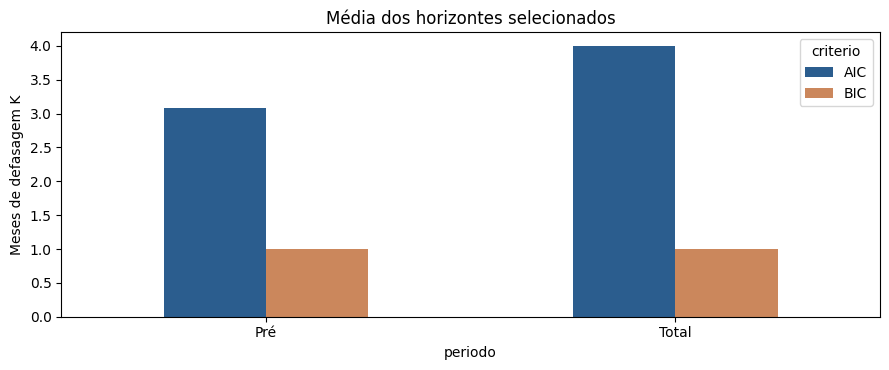

In [7]:
P=S.pivot_table(index=['periodo','tipologia'],columns='criterio',values='K',aggfunc='first').reset_index()
P['diferem']=P.AIC.ne(P.BIC)
print('Diferenças AIC/BIC:',int(P.diferem.sum()),'| BIC K=1:',int((P.BIC==1).sum()))
display(P[P.diferem].reset_index(drop=True))
fig,ax=plt.subplots(figsize=(9,3.8));P.dropna().groupby('periodo')[['AIC','BIC']].mean().plot(kind='bar',ax=ax,color=['#2b5d8e','#cb875c']);ax.set_title('Média dos horizontes selecionados');ax.set_ylabel('Meses de defasagem K');ax.tick_params(axis='x',rotation=0);plt.tight_layout();plt.show()

## 5. Comparação pooled, efeitos fixos e aleatórios

Nos modelos BIC K selecionados, o teste F compara a especificação com interceptos UF versus pooled, o LM de Breusch–Pagan avalia um componente aleatório estadual e Hausman compara inclinações FE/RE quando a matriz de diferença de covariâncias permite. A adoção de TWFE aqui decorre do estimando e do projeto, **não** de procurar significância.

In [8]:
D=pd.read_csv(OUT/'dlm_diagnosticos_fe_re.csv')
print('Testes FE/RE:',len(D))
print('F rejeitados:',int((D.p_F<.05).sum()),'LM rejeitados:',int((D.p_LM<.05).sum()),'Hausman disponíveis:',int(D.p_Hausman.notna().sum()),'Hausman rejeitados:',int((D.p_Hausman<.05).sum()))
display(D[['periodo','tipologia','K','p_F','p_LM','p_Hausman','theta_RE','media_absoluta','n_UFs_LB_p05']].head(10))

Testes FE/RE: 29
F rejeitados: 0 LM rejeitados: 0 Hausman disponíveis: 22 Hausman rejeitados: 0


,periodo,tipologia,K,p_F,p_LM,p_Hausman,theta_RE,media_absoluta,n_UFs_LB_p05
0,Pré,tipo_alagamentos,1,0.999889,1.0,0.556612,0.0,0.189883,12
1,Pré,tipo_chuvas_intensas,1,0.999893,1.0,0.703192,0.0,0.190910,12
2,Pré,tipo_doencas_infecciosas,1,0.999890,1.0,NaN,0.0,0.190245,13
3,Pré,tipo_enxurradas,1,0.999889,1.0,0.694005,0.0,0.190048,12
4,Pré,tipo_erosao,1,0.999893,1.0,0.784738,0.0,0.190287,13
5,Pré,tipo_estiagem_e_seca,1,0.999891,1.0,0.987544,0.0,0.190734,12
6,Pré,tipo_granizo,1,0.999890,1.0,0.985056,0.0,0.190370,12
7,Pré,tipo_incendio_florestal,1,0.999891,1.0,NaN,0.0,0.191500,13
8,Pré,tipo_inundacoes,1,0.999886,1.0,0.542312,0.0,0.189586,13
9,Pré,tipo_movimento_de_massa,1,0.999893,1.0,0.758409,0.0,0.190586,12


## 6. Testes e correções de multiplicidade

Ajustamos quatro estimadores de covariância nos *mesmos coeficientes MQO*: cluster UF, DK regra (L=floor[4(T/100)^(2/9)]), DK6 e DK12. **K é horizonte físico do DLM; L é banda HAC dos resíduos**, não são a mesma coisa. A escolha da banda modifica erros-padrão e p-valores, nunca os coeficientes.

As cinco hipóteses são: (1) β₀=0; (2) Σ₀ᴷβₖ=0; (3) Σ₁ᴷβₖ=0; (4) β₀=…=βᴷ=0; (5) β₁=…=βᴷ=0. Contrastes únicos usam t; conjuntos, Wald-F. BH atua dentro de famílias separadas por período × critério × covariância × hipótese. A proteção exploratória `min(24p,1)` é conservadora, mas **não constitui inferência pós-seleção exata**.

In [9]:
H=pd.read_csv(OUT/'dlm_hipoteses.csv')
summary=(H.groupby(['criterio','covariancia'])[['rejeicao_nominal','rejeicao_bh','rejeicao_bh_grade']].sum().reset_index())
display(summary.sort_values(['criterio','covariancia']))
print('BIC + DK regra:',int(H.query("criterio=='BIC' and covariancia=='dk_regra'").rejeicao_bh_grade.sum()))
print('AIC + DK regra:',int(H.query("criterio=='AIC' and covariancia=='dk_regra'").rejeicao_bh_grade.sum()))
display(H[H.rejeicao_bh_grade][['periodo','tipologia','criterio','K','covariancia','endpoint','p','q_bh_grade']].sort_values(['criterio','periodo','tipologia']).reset_index(drop=True))

,criterio,covariancia,rejeicao_nominal,rejeicao_bh,rejeicao_bh_grade
0,AIC,cluster_uf,36,28,11
1,AIC,dk12,51,37,18
2,AIC,dk6,46,36,6
3,AIC,dk_regra,44,35,4
4,BIC,cluster_uf,25,9,0
5,BIC,dk12,37,22,3
6,BIC,dk6,34,19,0
7,BIC,dk_regra,32,19,0


BIC + DK regra: 0
AIC + DK regra: 4


,periodo,tipologia,criterio,K,covariancia,endpoint,p,q_bh_grade
0,Pré,tipo_chuvas_intensas,AIC,15,dk_regra,conjunto0K,8.239061e-11,1.581900e-08
1,Pré,tipo_chuvas_intensas,AIC,15,dk_regra,conjunto1K,2.876591e-08,5.523055e-06
2,Pré,tipo_chuvas_intensas,AIC,15,dk6,conjunto0K,4.932415e-14,9.470237e-12
3,Pré,tipo_chuvas_intensas,AIC,15,dk6,conjunto1K,4.671841e-09,8.969935e-07
4,Pré,tipo_chuvas_intensas,AIC,15,dk12,conjunto0K,2.689545e-20,5.163927e-18
5,Pré,tipo_chuvas_intensas,AIC,15,dk12,conjunto1K,5.016389e-13,9.631467e-11
6,Pré,tipo_vendavais_e_ciclones,AIC,14,cluster_uf,conjunto0K,2.923491e-05,1.122621e-02
7,Pré,tipo_vendavais_e_ciclones,AIC,14,dk_regra,conjunto0K,8.379513e-13,3.217733e-10
8,Pré,tipo_vendavais_e_ciclones,AIC,14,dk_regra,conjunto1K,1.039004e-12,3.989777e-10
9,Pré,tipo_vendavais_e_ciclones,AIC,14,dk6,conjunto0K,5.998332e-19,2.303360e-16


## 7. Auditoria numérica de K elevados e correlação residual

Calculamos posto e número de condição dos regressores de cada modelo selecionado, além de autovalores e condicionamento da covariância. Esse diagnóstico **não muda** a estimação nem seleciona modelos com base em significância. Se os critérios auditados não apontarem singularidade, diferenças de p entre AIC/BIC/bandas ainda exigem interpretação de sensibilidade.

In [10]:
def auditoria_dlm(data):
    selections=pd.read_csv(OUT/'dlm_selecao.csv')
    tests=pd.read_csv(OUT/'dlm_hipoteses.csv')
    detail=[]
    for per,stop in [('Pré','2020-01'),('Total','2024-12')]:
        g=data[data.mes_ano<=stop]; ufs=sorted(g.uf.unique());t=g.mes_ano.nunique()
        y=np.stack([g[g.uf==u].y.to_numpy(float) for u in ufs])
        for tipo in TIPOS:
            xs=np.stack([g[g.uf==u]['x_'+tipo].to_numpy(float) for u in ufs])
            for crit in ['AIC','BIC']:
                rows=selections[(selections.periodo==per)&(selections.tipologia==tipo)&(selections.criterio==crit)]
                assert len(rows)==1,(per,tipo,crit)
                if rows.iloc[0].status!='estimado':continue
                K=int(rows.iloc[0].K)
                X,Y,T=design_panel(xs,y,K,t,len(ufs))
                sing=np.linalg.svd(X,compute_uv=False)
                rank=int(np.linalg.matrix_rank(X))
                cond=float(sing[0]/sing[-1]) if sing[-1]>0 else np.inf
                b=np.linalg.lstsq(X,Y,rcond=None)[0];e=Y-X@b
                for band in ['cluster_uf','dk_regra','dk6','dk12']:
                    V,df_res=robust_cov(X,e,K,27,T,band)
                    eig=np.linalg.eigvalsh(V)
                    # Comparação entre menores e maiores valores singulares da covariância
                    sv=np.linalg.svd(V,compute_uv=False)
                    cV=float(sv[0]/sv[-1]) if sv[-1]>0 else np.inf
                    nneg=int((eig<=0).sum())
                    past=tests[(tests.periodo==per)&(tests.tipologia==tipo)&(tests.criterio==crit)&(tests.covariancia==band)]
                    out={
                     'periodo':per,'tipologia':tipo,'criterio':crit,'K':K,'covariancia':band,
                     'n_obs':len(Y),'n_coef':K+1,'posto_X':rank,'cond_X':cond,
                     'min_sv_X':float(sing[-1]),'max_sv_X':float(sing[0]),
                     'cond_cov':cV,'min_eig_cov':float(eig[0]),'max_eig_cov':float(eig[-1]),
                     'n_eig_cov_nao_positivos':nneg,'cov_postocompleto':nneg==0,
                     'alerta_cond_X':cond>1e3, 'alerta_cond_cov':cV>1e6,
                     'n_rejeicoes_grade_BH':int((past.q_bh_grade<.05).sum()),
                     'endpoints_rejeitados_grade_BH':';'.join(past.loc[past.q_bh_grade<.05,'endpoint'].tolist()),
                     'soma_0K':float(b.sum()),'soma_1K':float(b[1:].sum())}
                    detail.append(out)
    d=pd.DataFrame(detail).sort_values(['periodo','tipologia','criterio','covariancia'])
    d.to_csv(AUD/'dlm_matrizes_condicionamento.csv',index=False,encoding='utf-8-sig')
    return d

In [11]:
M=auditoria_dlm(df)
print('Ajustes auditados:',len(M)//4,'| alertas cond X > 1000:',int(M[M.covariancia=='dk_regra'].alerta_cond_X.sum()),'| alertas cov > 1e6:',int(M.alerta_cond_cov.sum()))
display(M[(M.n_rejeicoes_grade_BH>0)&(M.covariancia=='dk_regra')][['periodo','tipologia','criterio','K','posto_X','cond_X','cond_cov','endpoints_rejeitados_grade_BH']])

Ajustes auditados: 58 | alertas cond X > 1000: 0 | alertas cov > 1e6: 0


,periodo,tipologia,criterio,K,posto_X,cond_X,cond_cov,endpoints_rejeitados_grade_BH
9,Pré,tipo_chuvas_intensas,AIC,15,16,7.035885,1280.753254,conjunto0K;conjunto1K
97,Pré,tipo_vendavais_e_ciclones,AIC,14,15,10.568839,973.326940,conjunto0K;conjunto1K


## 8. Perfis β por defasagem e curvas acumuladas

Para cada tipologia, critério e covariância, calculamos \(\hat\beta_0,\dots,\hat\beta_K\) e \(C(h)=\sum_{k=0}^{h}\hat\beta_k\), com IC de 95% obtidos pela covariância completa. As curvas descrevem **associação acumulada sob as transformações adotadas**, não uma variação automática em pontos percentuais na taxa de inadimplência.

In [12]:
from scipy.stats import t as tdist

def construir_perfis_dlm():
    perfis=[];acums=[]
    for per,stop in [('Pré','2020-01'),('Total','2024-12')]:
        g=df[df.mes_ano<=stop];uf=sorted(g.uf.unique());Ttotal=g.mes_ano.nunique()
        yy=np.stack([g[g.uf==i].y.to_numpy(float) for i in uf])
        for typ in TIPOS:
            xx=np.stack([g[g.uf==i]['x_'+typ].to_numpy(float) for i in uf])
            for crit in ['AIC','BIC']:
                selected=S[(S.periodo==per)&(S.tipologia==typ)&(S.criterio==crit)]
                if selected.iloc[0].status!='estimado':continue
                K=int(selected.iloc[0].K); X,Y,T=design_panel(xx,yy,K,Ttotal,len(uf));b=np.linalg.lstsq(X,Y,rcond=None)[0];e=Y-X@b
                for cov in ['dk_regra','dk6','dk12','cluster_uf']:
                    V,dfr=robust_cov(X,e,K,27,T,cov);crit95=tdist.ppf(.975,dfr)
                    for k in range(K+1):
                        se=np.sqrt(max(0.,V[k,k]));w=np.zeros(K+1);w[:k+1]=1
                        v=float(w@V@w);sc=np.sqrt(max(0.,v));cum=float(w@b)
                        meta={'periodo':per,'tipologia':typ,'criterio':crit,'K':K,'covariancia':cov}
                        perfis.append({**meta,'k':k,'coef_beta_k':float(b[k]),'se':se,'ic95_inf':float(b[k]-crit95*se),'ic95_sup':float(b[k]+crit95*se),'n':len(Y)})
                        acums.append({**meta,'h':k,'acum_0h':cum,'se_acum':sc,'ic95_inf':cum-crit95*sc,'ic95_sup':cum+crit95*sc,'n':len(Y)})
    prof=pd.DataFrame(perfis);curve=pd.DataFrame(acums)
    prof.to_csv(AUD/'dlm_betas_por_lag.csv',index=False,encoding='utf-8-sig')
    curve.to_csv(AUD/'dlm_resposta_acumulada.csv',index=False,encoding='utf-8-sig')
    return prof,curve
PERFIL,CURVA=construir_perfis_dlm()
print('Coeficientes individuais:',len(PERFIL),'| pontos de curvas acumuladas:',len(CURVA))

Coeficientes individuais: 764 | pontos de curvas acumuladas: 764


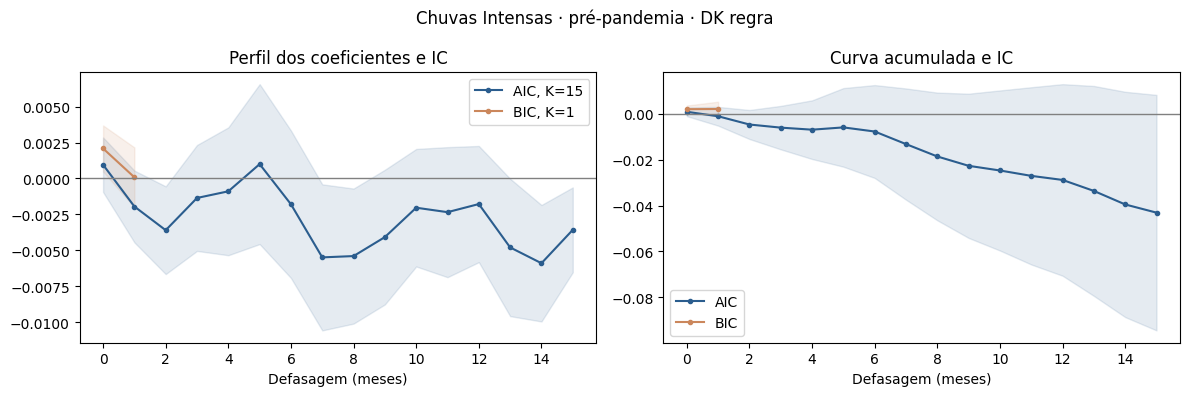

In [13]:
# Exemplo interpretável: mesma tipologia no pré-pandemia, horizontes AIC×BIC.
per='Pré';typ='tipo_chuvas_intensas';kind='dk_regra'
fig,axs=plt.subplots(1,2,figsize=(12,4))
for crit,color in [('AIC','#2b5d8e'),('BIC','#cb875c')]:
    p=PERFIL.query('periodo==@per and tipologia==@typ and criterio==@crit and covariancia==@kind').sort_values('k')
    c=CURVA.query('periodo==@per and tipologia==@typ and criterio==@crit and covariancia==@kind').sort_values('h')
    axs[0].plot(p.k,p.coef_beta_k,marker='o',markersize=3,label=f'{crit}, K={int(p.K.iloc[0])}',color=color)
    axs[0].fill_between(p.k,p.ic95_inf,p.ic95_sup,color=color,alpha=.12)
    axs[1].plot(c.h,c.acum_0h,marker='o',markersize=3,label=crit,color=color)
    axs[1].fill_between(c.h,c.ic95_inf,c.ic95_sup,color=color,alpha=.12)
for ax in axs:ax.axhline(0,color='gray',linewidth=1);ax.set_xlabel('Defasagem (meses)');ax.legend()
axs[0].set_title('Perfil dos coeficientes e IC');axs[1].set_title('Curva acumulada e IC')
plt.suptitle('Chuvas Intensas · pré-pandemia · DK regra');plt.tight_layout();plt.show()

## 9. Síntese e limitações

O **BIC escolheu K=1 em todos os 29 casos estimáveis**; AIC escolheu K maior em oito. É importante lembrar que K=1 é o menor valor da grade: a seleção **não demonstra** que efeitos posteriores a um mês sejam impossíveis. AIC + DK regra teve quatro rejeições protegidas; BIC + DK regra, nenhuma. Alterar DK modifica a conclusão de alguns testes, apesar de não modificar os β estimados.

As comparações são descritivas/associativas; efeitos fixos controlam heterogeneidade fixa e choques comuns por mês, não eliminam todos os confundidores. A inferência sobre K escolhido e múltiplas hipóteses continua exploratória. **Saídas:** `dlm_candidatos.csv`, `dlm_selecao.csv`, `dlm_hipoteses.csv`, `dlm_diagnosticos_fe_re.csv` e, para gráficos, `dlm_betas_por_lag.csv` e `dlm_resposta_acumulada.csv`.

## 10. Complemento: os dois menores AICs

A auditoria posterior à unificação dos notebooks examinou a primeira e a
segunda escolha de K em cada período e tipologia. **Todos os 29 casos
estimáveis têm ΔAIC inferior a 2**, mas essa proximidade é parcialmente
esperada por construção: os modelos com K e K+1 são aninhados e usam a mesma
amostra, de modo que `AIC(K+1) − AIC(K) ≤ 2` se o candidato K+1 estiver
disponível. Isso **não** equivale à significância da nova defasagem.

A inferência foi recalculada sob os dois K com DK por regra, DK6 e DK12,
Bonferroni para a busca de K e Holm entre tipologias. Sob **DK por regra, nenhuma
rejeição sobrevive aos ajustes em ambas as escolhas**. Veja a
`docs/nota_defasagens_20261024.md` para a metodologia completa. A célula abaixo
exibe as tabelas auditadas produzidas pelos scripts complementares de `src/`.

In [ ]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown

_raiz = Path.cwd().resolve()
if _raiz.name == 'notebooks': _raiz = _raiz.parent
_dir = _raiz / 'outputs/tables/revisao_defasagens_20261024'
_duas = pd.read_csv(_dir / 'dlm_dois_menores_aic.csv', encoding='utf-8-sig')
_dk = pd.read_csv(_dir / 'resumo_inferencia_top2.csv', encoding='utf-8-sig')
display(Markdown('**Defasagens escolhidas pelos dois menores AICs**'))
display(_duas[['periodo','tipologia','K_menor_AIC','K_segundo_AIC','delta_AIC']].round(3))
display(Markdown('**Hipóteses rejeitadas após os ajustes — comparação entre K**'))
display(_dk.pivot(index='posicao_AIC', columns='banda_DK', values='com_ajustes'))

## 11. Sensibilidade: horizontes comuns de 6 e 12 meses

A grade anterior começou em K=1. Uma auditoria com K=0 na mesma amostra
mostrou AIC menor em 18 das 29 combinações estimáveis, sendo 17 casos que
tinham escolhido K=1. Assim, a grade anterior não permitia concluir que
um mês de atraso fosse necessário em todos esses modelos.

Como alternativa, foram estimados dois DLMs finitos irrestritos com
**K=12 como horizonte de referência** e K=6 como sensibilidade, mantendo
TWFE, transformações e amostra comum. DK por regra permanece a inferência
principal. A proteção de Holm abrange simultaneamente os dois horizontes e
16 tipologias planejadas; testes conjuntos usam união de testes individuais.

Após o ajuste, K=12/DK por regra apresentou zero rejeições, enquanto
K=6/DK por regra apresentou duas hipóteses conjuntas rejeitadas para
Movimento de Massa no período completo. O resultado não foi estável no
horizonte anual. A proposta é exploratória, pois os horizontes foram
escolhidos após a inspeção dos resultados anteriores.

O código reproduzível e a interpretação detalhada estão em
`src/dlm_horizontes_predefinidos.py` e
`docs/revisao_dlm_horizontes_fixos_20261024.md`.

In [ ]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown

_raiz = Path.cwd().resolve()
if _raiz.name == 'notebooks': _raiz = _raiz.parent
_dir = _raiz / 'outputs/tables/dlm_horizontes_fixos_20261024'
_k0 = pd.read_csv(_dir / 'k0_comparacao_aic.csv', encoding='utf-8-sig')
_fixos = pd.read_csv(_dir / 'resumo_inferencia.csv', encoding='utf-8-sig')
display(Markdown(f'**K=0 superaria a escolha original em {int(_k0.K0_seria_preferido.sum())} de {len(_k0)} combinações.**'))
display(Markdown('**Hipóteses rejeitadas após Holm — horizontes comuns**'))
display(_fixos.pivot(index='K', columns='banda', values='rejeicoes_apos_ajuste'))